In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load in

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the "../input/" directory.
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# Any results you write to the current directory are saved as output.

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style('darkgrid')

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
df = pd.read_csv("/content/drive/MyDrive/22007860-KANGNI-SOUKPE-Kangni-Roger-G2/Finance_data.csv")

In [5]:
df.head()

,gender,age,Investment_Avenues,Mutual_Funds,Equity_Market,Debentures,Government_Bonds,Fixed_Deposits,PPF,Gold,...,Duration,Invest_Monitor,Expect,Avenue,What are your savings objectives?,Reason_Equity,Reason_Mutual,Reason_Bonds,Reason_FD,Source
0,Female,34,Yes,1,2,5,3,7,6,4,...,1-3 years,Monthly,20%-30%,Mutual Fund,Retirement Plan,Capital Appreciation,Better Returns,Safe Investment,Fixed Returns,Newspapers and Magazines
1,Female,23,Yes,4,3,2,1,5,6,7,...,More than 5 years,Weekly,20%-30%,Mutual Fund,Health Care,Dividend,Better Returns,Safe Investment,High Interest Rates,Financial Consultants
2,Male,30,Yes,3,6,4,2,5,1,7,...,3-5 years,Daily,20%-30%,Equity,Retirement Plan,Capital Appreciation,Tax Benefits,Assured Returns,Fixed Returns,Television
3,Male,22,Yes,2,1,3,7,6,4,5,...,Less than 1 year,Daily,10%-20%,Equity,Retirement Plan,Dividend,Fund Diversification,Tax Incentives,High Interest Rates,Internet
4,Female,24,No,2,1,3,6,4,5,7,...,Less than 1 year,Daily,20%-30%,Equity,Retirement Plan,Capital Appreciation,Better Returns,Safe Investment,Risk Free,Internet


In [6]:
df.drop(['Mutual_Funds', 'Equity_Market',
       'Debentures', 'Government_Bonds', 'Fixed_Deposits', 'PPF', 'Gold'],axis=1,inplace=True)

/tmp/ipykernel_2344/3866990895.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(df['gender'],linewidth=3,palette="Set2",edgecolor='black')


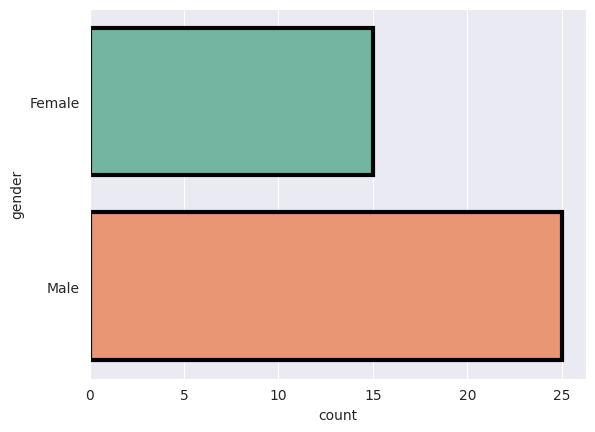

In [7]:
# First we will see Gender of our respondenets
sns.countplot(df['gender'],linewidth=3,palette="Set2",edgecolor='black')
plt.show()

/tmp/ipykernel_2344/2206887869.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(df['age'],palette="Set3",linewidth=2,edgecolor='black')


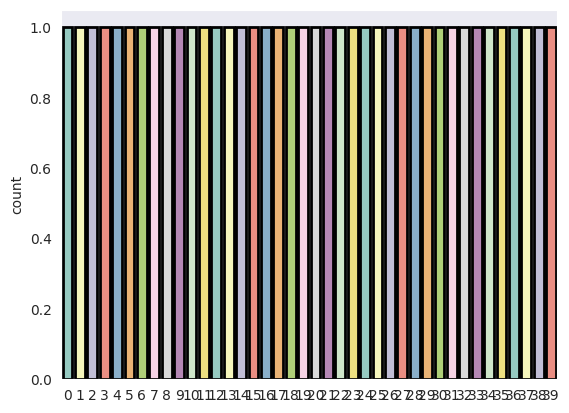

In [8]:
# Now we will see Age of our respondents
sns.countplot(df['age'],palette="Set3",linewidth=2,edgecolor='black')
plt.show()

We can see from the above graph that most of our respondents were in the ages 24-31 and we will look further
their habits in the finanace field

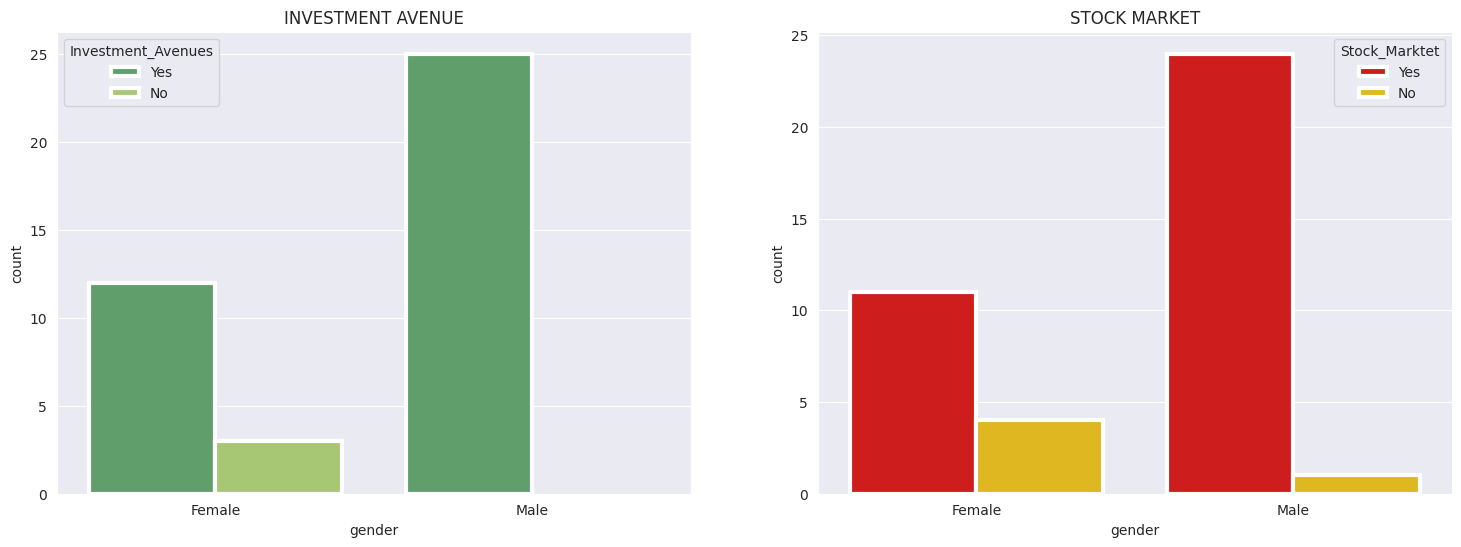

In [9]:
# Now lets see these same factors of INVESTMENT_AVENUE and STOCK_MARKET with gender

plt.figure(figsize=(18,6))
plt.subplot(1, 2, 1)
sns.countplot(x=df['gender'],hue=df['Investment_Avenues'],palette='summer',linewidth=3,edgecolor='white')
plt.title('INVESTMENT AVENUE')
plt.subplot(1, 2, 2)
sns.countplot(x=df['gender'],hue=df['Stock_Marktet'],palette='hot',linewidth=3,edgecolor='white')
plt.title('STOCK MARKET')
plt.show()


# Mostly females dont invest or go to stocks

/tmp/ipykernel_2344/3847998600.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df['Factor'],palette='coolwarm',linewidth=2,edgecolor='black')


<Axes: xlabel='Factor', ylabel='count'>

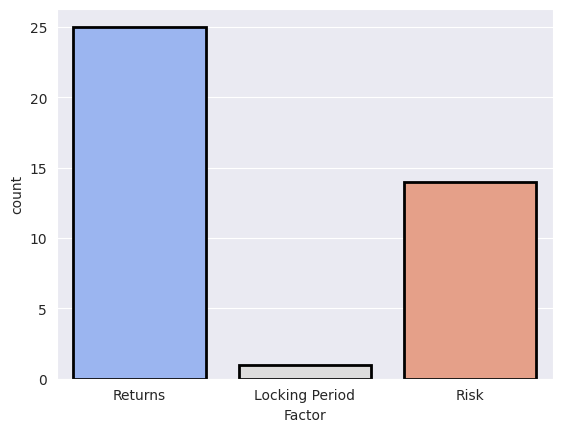

In [10]:
# Factors affecting Investing
sns.countplot(x=df['Factor'],palette='coolwarm',linewidth=2,edgecolor='black')

# Returns is the most influential Factor considered while investing which is followed by risk

The above trend shows us that people are less worried about risks involved and more worried about the money which they will get back

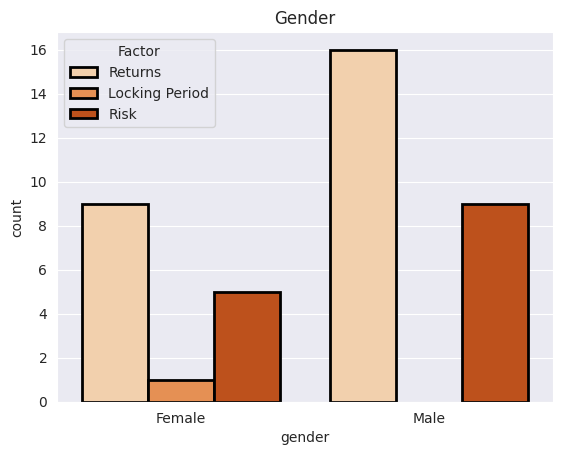

In [11]:
# Lets see which Age groups take the highest risk
sns.countplot(x=df['gender'],hue=df['Factor'],palette='Oranges',linewidth=2,edgecolor='black')
plt.title('Gender')
plt.show()


We can see that high number of males are dependent on Returns

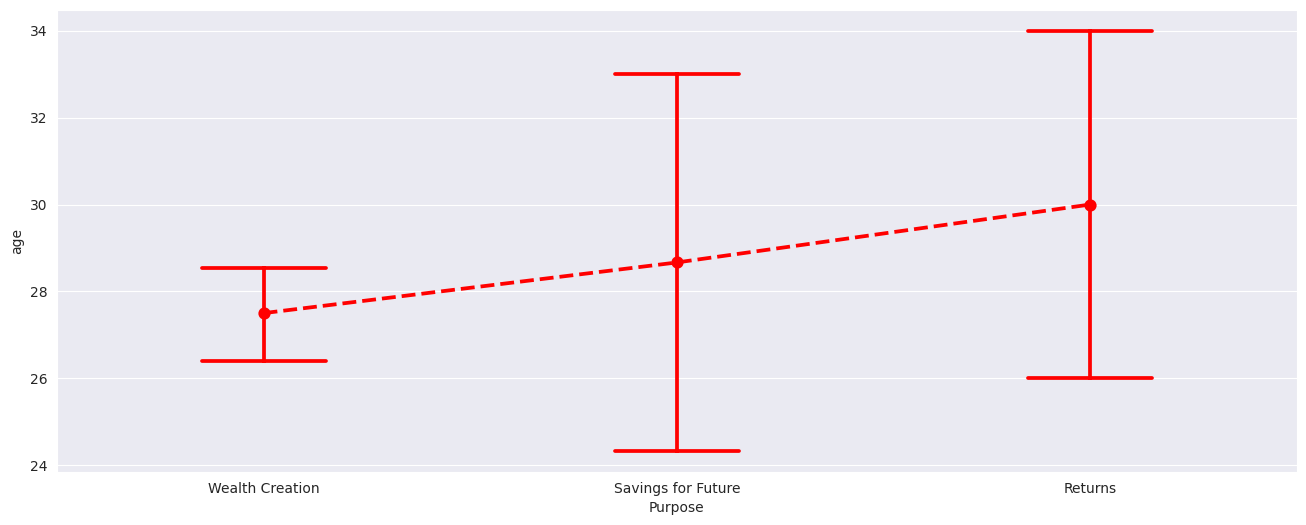

In [12]:
plt.figure(figsize=(16,6))
sns.pointplot(x="Purpose",y='age',data=df,linestyles="--",capsize=.3,color='Red')
plt.show()

From the above plot it is clear that as people grow older they are more inclined towards Returns and people at young age look more for wealth creation

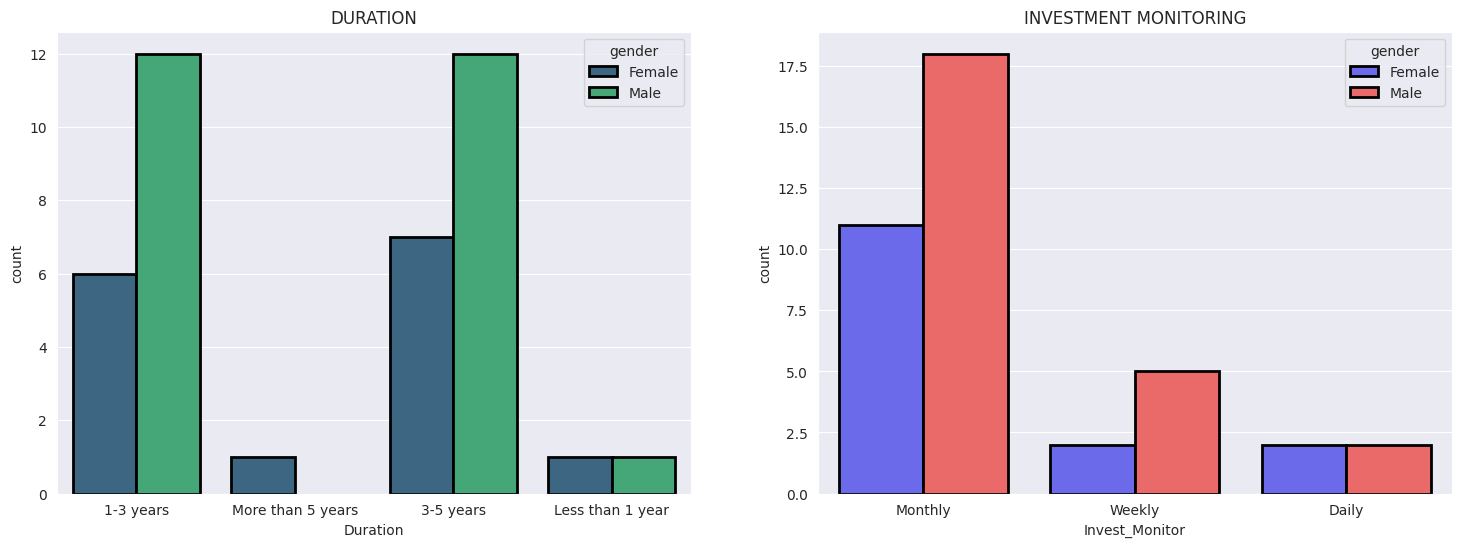

In [13]:
# Now lets see these same factors of Duration and Invest_monitor with gender

plt.figure(figsize=(18,6))
plt.subplot(1, 2, 1)
sns.countplot(hue=df['gender'],x=df['Duration'],palette='viridis',linewidth=2,edgecolor='black')
plt.title('DURATION')
plt.subplot(1, 2, 2)
sns.countplot(hue=df['gender'],x=df['Invest_Monitor'],palette='seismic',linewidth=2,edgecolor='black')
plt.title('INVESTMENT MONITORING')
plt.show()

#Below graphs show us that most of the people invest from 1-5 Years and monitor their investments mostly monthly


# F24 — Corrélation glissante entre le Nasdaq et le S&P 500

## 1. Contexte et problématique

Le Nasdaq Composite et le S&P 500 sont deux indices boursiers majeurs du marché américain. Leurs évolutions peuvent être liées, mais l'intensité de leur relation varie au cours du temps en fonction des conditions économiques et financières.

L'étude de leur corrélation glissante permet d'observer l'évolution de cette relation sur une période donnée et d'identifier ses changements.

**Problématique :**

À partir des rendements historiques du Nasdaq et du S&P 500, peut-on prédire si leur corrélation augmentera ou diminuera au cours des 20 prochaines séances boursières ?

## 1.1 Objectif du projet

L'objectif est de construire un modèle de Machine Learning capable de prédire le sens d'évolution de la corrélation entre les deux indices, en utilisant leurs données historiques.

Pour cela, nous allons :

- Collecter les données historiques du Nasdaq Composite et du S&P 500 à partir de Yahoo Finance, à l'aide de la bibliothèque Python `yfinance`.
- Calculer leurs rendements journaliers.
- Calculer leur corrélation glissante sur une fenêtre de 60 séances.
- Construire une variable cible binaire correspondant à l'évolution future de la corrélation sur 20 séances.
- Entraîner et évaluer un modèle de classification par régression logistique.

## 1.2 Nature du problème

- **Type d'apprentissage :** apprentissage supervisé.
- **Tâche :** classification binaire.
- **Algorithme principal :** régression logistique.
- **Fenêtre d'observation :** 60 séances boursières.
- **Horizon de prévision :** 20 séances boursières.

## 1.3 Définition de la variable cible

La variable cible est définie selon deux classes :

- **Classe 0 :** la corrélation diminue ou reste stable.
- **Classe 1 :** la corrélation augmente.

La variable cible est construite à partir de la comparaison entre la corrélation glissante observée à la date de prévision et celle observée 20 séances plus tard.



## 2. Compréhension et chargement des données

### 2.1. Sources des données

Les données utilisées dans cette étude proviennent de la plateforme Yahoo Finance.

Deux séries financières journalières sont utilisées :
- ^IXIC : indice Nasdaq Composite.
- ^GSPC : indice S&P 500.

Les observations correspondent aux valeurs de clôture quotidiennes des deux indices. La période d'étude sera déterminée à partir de leur période commune de disponibilité.


In [14]:

!pip install yfinance


In [15]:

import yfinance as yf
import pandas as pd
import numpy as np

# Définition de la période
date_debut = "2016-11-17"
date_fin = "2026-11-17"

# Téléchargement séparé des deux indices
nasdaq = yf.download(
    "^IXIC",
    start=date_debut,
    end=date_fin,
    auto_adjust=True,
    progress=False
)

sp500 = yf.download(
    "^GSPC",
    start=date_debut,
    end=date_fin,
    auto_adjust=True,
    progress=False
)

# Extraction des prix de clôture
donnees = pd.DataFrame({
    "Nasdaq": nasdaq["Close"].squeeze(),
    "SP500": sp500["Close"].squeeze()
})

# Conservation des dates communes
donnees = donnees.dropna()

# Vérification
print("Dimensions :", donnees.shape)
print("Date de début :", donnees.index.min())
print("Date de fin :", donnees.index.max())

print("\nValeurs manquantes :")
print(donnees.isnull().sum())

print("\nPremières observations :")
display(donnees.head())

print("\nDernières observations :")
display(donnees.tail())


Dimensions : (2512, 2)
Date de début : 2016-11-17 00:00:00
Date de fin : 2026-11-16 00:00:00

Valeurs manquantes :
Nasdaq    0
SP500     0
dtype: int64

Premières observations :


,Nasdaq,SP500
Date,,
2016-11-17,5333.970215,2187.120117
2016-11-18,5321.509766,2181.899902
2016-11-21,5368.859863,2198.179932
2016-11-22,5386.350098,2202.939941
2016-11-23,5380.680176,2204.719971



Dernières observations :


,Nasdaq,SP500
Date,,
2026-11-10,25065.869141,7520.930176
2026-11-11,25466.189453,7619.379883
2026-11-12,25366.089844,7592.399902
2026-11-13,25136.269531,7561.669922
2026-11-16,24509.759766,7416.589844


### 2.2. Présentation et provenance du jeu de données

Les données de cette étude proviennent de Yahoo Finance. Elles concernent deux indices majeurs du marché boursier américain : le Nasdaq Composite et le S&P 500.

Les données ont été téléchargées à l'aide de la bibliothèque Python `yfinance`, à partir de leurs symboles respectifs `^IXIC` et `^GSPC`.

**Caractéristiques du jeu de données :**

- Source : Yahoo Finance.
- Organisme : Yahoo Finance.
- Date d'extraction : 17 novembre 2026.
- Période étudiée : du 17 novembre 2016 au 16 novembre 2026.
- Fréquence : quotidienne.
- Unité d'observation : une séance boursière.
- Nombre d'observations communes : 2 512.
- Variables initiales : prix de clôture des deux indices.
- Valeurs manquantes après alignement : aucune.

**Liens des sources :**
- Nasdaq Composite : https://finance.yahoo.com/quote/%5EIXIC/history/
- S&P 500 : https://finance.yahoo.com/quote/%5EGSPC/history/

La récupération des données est effectuée avec `yfinance`, en utilisant `auto_adjust=True`. Les conditions d'utilisation de Yahoo Finance s'appliquent aux données récupérées ; celles-ci ne doivent pas être considérées comme disposant automatiquement d'une licence ouverte de redistribution.

In [16]:

# Vérification finale de la structure des données

print("Types des variables :")
print(donnees.dtypes)

print("\nDates chronologiquement ordonnées :")
print(donnees.index.is_monotonic_increasing)

print("\nDates dupliquées :")
print(donnees.index.duplicated().sum())

print("\nStatistiques descriptives :")
display(donnees.describe())


Types des variables :
Nasdaq    float64
SP500     float64
dtype: object

Dates chronologiquement ordonnées :
True

Dates dupliquées :
0

Statistiques descriptives :


,Nasdaq,SP500
count,2512.000000,2512.000000
mean,13167.950564,4229.730000
std,5788.660561,1521.219739
min,5251.109863,2181.899902
25%,7901.417480,2873.222595
50%,12349.064941,4016.584961
75%,16371.922607,5234.505127
max,27599.789062,7818.930176


## 3. Analyse exploratoire des données (EDA)

L'analyse exploratoire vise à comprendre l'évolution historique du Nasdaq Composite et du S&P 500, à examiner leurs rendements journaliers et à identifier les principales caractéristiques statistiques des séries avant la construction du modèle de Machine Learning.

### 3.1. Calcul des rendements journaliers

Les rendements journaliers permettent de mesurer la variation relative de chaque indice entre deux séances boursières consécutives. Ils facilitent la comparaison des évolutions des deux marchés indépendamment de leurs niveaux respectifs.

In [17]:

# Calcul des rendements journaliers en pourcentage

rendements = donnees.pct_change(fill_method=None) * 100

# Suppression de la première ligne (absence de séance précédente)
rendements = rendements.dropna()

# Affichage des résultats
print("Dimensions des rendements :", rendements.shape)

print("\nPremières observations :")
display(rendements.head())

print("\nStatistiques descriptives des rendements :")
display(rendements.describe())


Dimensions des rendements : (2511, 2)

Premières observations :


,Nasdaq,SP500
Date,,
2016-11-18,-0.233606,-0.238680
2016-11-21,0.889787,0.746140
2016-11-22,0.325772,0.216543
2016-11-23,-0.105265,0.080802
2016-11-25,0.338986,0.391439



Statistiques descriptives des rendements :


,Nasdaq,SP500
count,2511.000000,2511.000000
mean,0.070652,0.055211
std,1.405714,1.144285
min,-12.321331,-11.984055
25%,-0.523452,-0.378265
50%,0.116765,0.079990
75%,0.796054,0.589882
max,12.163161,9.515388


### Interprétation des statistiques descriptives

L'analyse des rendements journaliers montre que le Nasdaq présente un rendement moyen de 0,0707 %, supérieur à celui du S&P 500 (0,0552 %) sur la période étudiée.

L'écart-type du Nasdaq (1,4057 %) est également supérieur à celui du S&P 500 (1,1443 %), ce qui traduit une plus forte dispersion de ses rendements journaliers. Les deux indices présentent par ailleurs des variations extrêmes, avec des rendements minimaux respectifs de -12,32 % et -11,98 %.

Ces premières observations suggèrent que le Nasdaq a connu des fluctuations quotidiennes plus importantes que le S&P 500 au cours de la période étudiée.

# 3.2. Premier graphique : évolution des deux indices

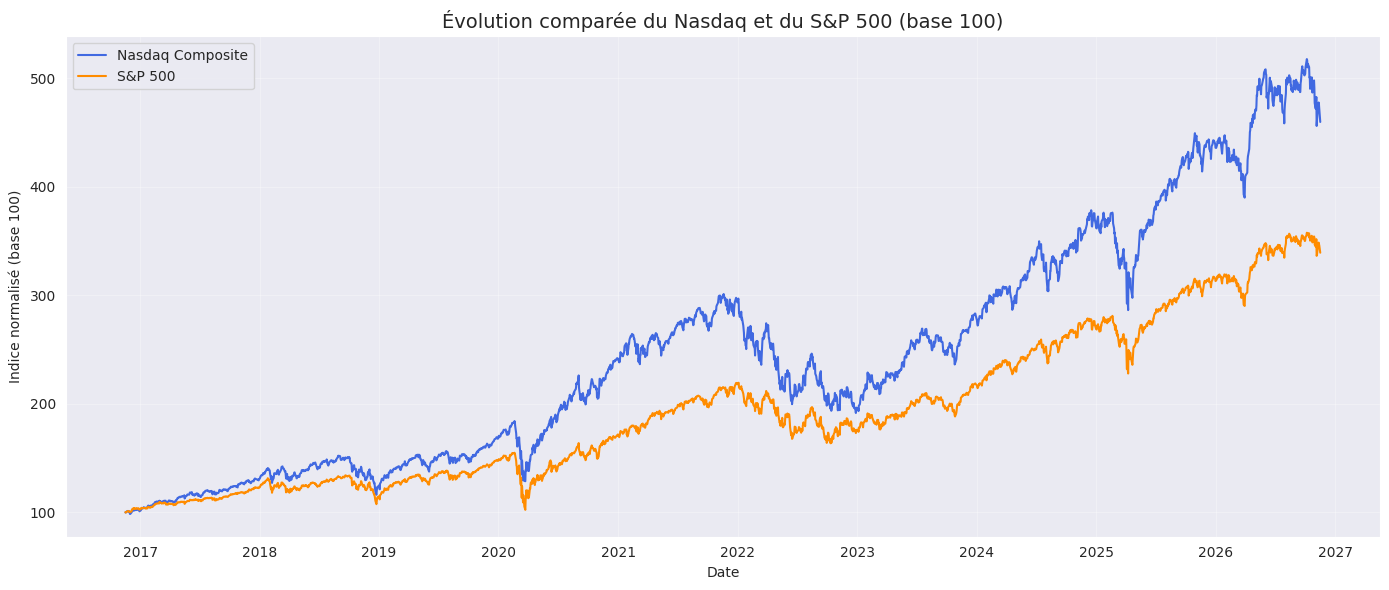

In [18]:

import matplotlib.pyplot as plt

# Normalisation des indices à une base 100
indices_normalises = donnees / donnees.iloc[0] * 100

# Graphique
plt.figure(figsize=(14, 6))

plt.plot(
    indices_normalises.index,
    indices_normalises["Nasdaq"],
    label="Nasdaq Composite",
    color="royalblue",
    linewidth=1.5
)

plt.plot(
    indices_normalises.index,
    indices_normalises["SP500"],
    label="S&P 500",
    color="darkorange",
    linewidth=1.5
)

plt.title("Évolution comparée du Nasdaq et du S&P 500 (base 100)",
          fontsize=14)
plt.xlabel("Date")
plt.ylabel("Indice normalisé (base 100)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Interprétation de l'évolution comparée des indices

Le graphique montre une tendance globalement haussière du Nasdaq Composite et du S&P 500 sur la période 2016-2026. Les deux indices connaissent des phases de baisse communes, notamment en 2020 et en 2022, ce qui suggère une certaine dépendance dans leurs évolutions.

Cependant, le Nasdaq affiche une progression plus importante. En prenant la valeur initiale comme base 100, il atteint environ 460 à la fin de la période, contre environ 340 pour le S&P 500. Cette différence traduit une performance cumulée supérieure du Nasdaq sur la période étudiée.

Ces observations descriptives ne suffisent toutefois pas à mesurer précisément la corrélation entre les deux indices. C'est pourquoi nous analyserons ensuite leurs rendements journaliers.

# 3.3. Deuxième graphique : évolution des rendements journaliers
Nous allons observer les variations quotidiennes des deux indices.

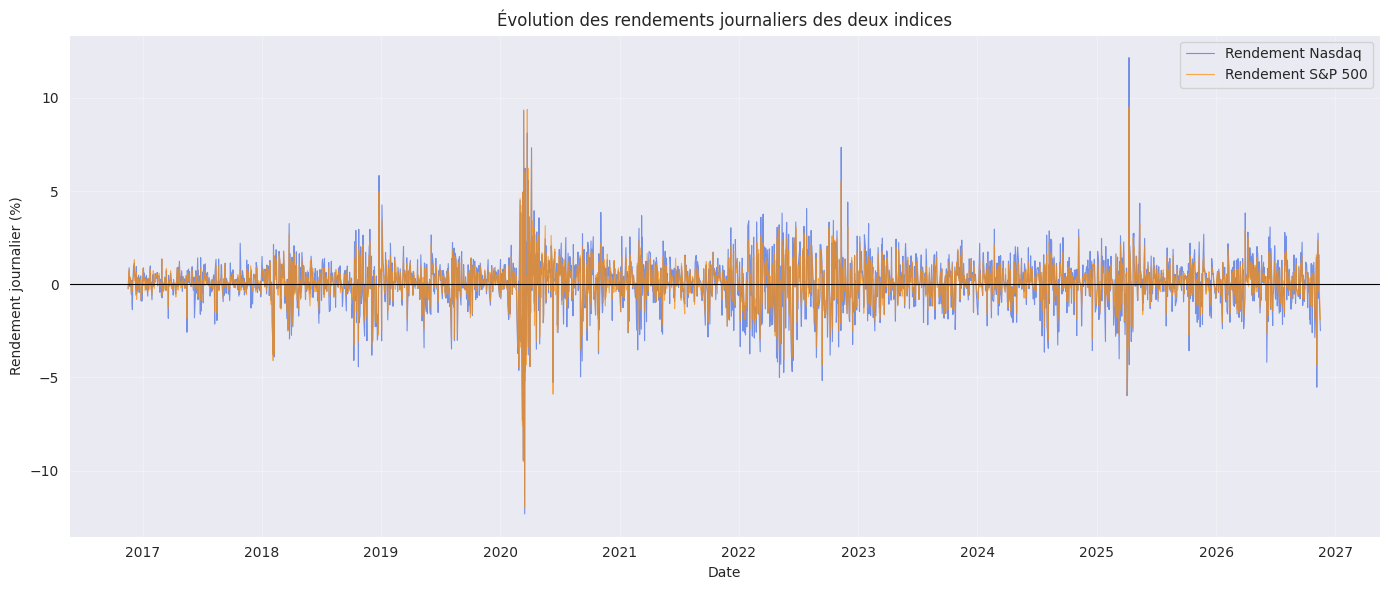

In [19]:

plt.figure(figsize=(14, 6))

plt.plot(
    rendements.index,
    rendements["Nasdaq"],
    label="Rendement Nasdaq",
    color="royalblue",
    alpha=0.7,
    linewidth=0.8
)

plt.plot(
    rendements.index,
    rendements["SP500"],
    label="Rendement S&P 500",
    color="darkorange",
    alpha=0.7,
    linewidth=0.8
)

plt.axhline(0, color="black", linewidth=0.8)

plt.title("Évolution des rendements journaliers des deux indices")
plt.xlabel("Date")
plt.ylabel("Rendement journalier (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Interprétation de l'évolution des rendements journaliers

Le graphique montre que les rendements journaliers des deux indices fluctuent généralement autour de zéro. Cela signifie que les variations quotidiennes peuvent être positives ou négatives.

On observe également des périodes de forte volatilité, notamment en 2020, lors de la crise sanitaire, ainsi qu'en 2022 et en 2025. Durant ces périodes, les deux indices enregistrent des variations importantes, souvent dans le même sens.

Le Nasdaq présente parfois des fluctuations plus amples que le S&P 500. Ces observations suggèrent une certaine dépendance entre les rendements des deux indices, mais aussi une variabilité de leur comportement au cours du temps.

# 3.4. Troisième graphique : distribution des rendements
Nous allons maintenant examiner la distribution statistique des rendements journaliers.

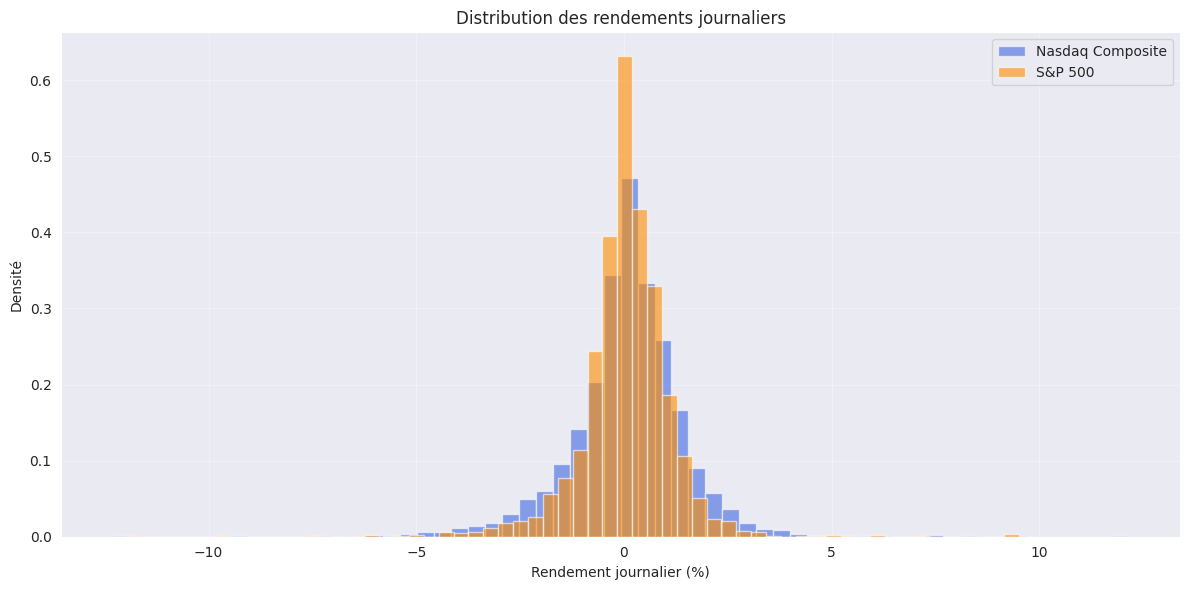

In [20]:

plt.figure(figsize=(12, 6))

plt.hist(
    rendements["Nasdaq"],
    bins=60,
    alpha=0.6,
    color="royalblue",
    label="Nasdaq Composite",
    density=True
)

plt.hist(
    rendements["SP500"],
    bins=60,
    alpha=0.6,
    color="darkorange",
    label="S&P 500",
    density=True
)

plt.title("Distribution des rendements journaliers")
plt.xlabel("Rendement journalier (%)")
plt.ylabel("Densité")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Interprétation de la distribution des rendements journaliers

Les deux distributions sont fortement concentrées autour de zéro, ce qui indique que la majorité des variations quotidiennes des deux indices restent relativement faibles.

La distribution du Nasdaq est plus étalée que celle du S&P 500, ce qui confirme la plus grande dispersion de ses rendements observée dans les statistiques descriptives.

On remarque également des observations situées loin du centre de la distribution, dans les deux directions. Ces valeurs extrêmes traduisent des journées de fortes variations sur les marchés financiers.

Globalement, les deux distributions présentent des caractéristiques proches, mais le Nasdaq semble connaître des fluctuations journalières plus importantes.

# 3.5. Vérification de la qualité des données


In [21]:

# Valeurs manquantes
print("Valeurs manquantes :")
print(donnees.isnull().sum())

# Dates dupliquées
print("\nDates dupliquées :")
print(donnees.index.duplicated().sum())

# Valeurs extrêmes : méthode de l'écart interquartile (IQR)
for colonne in rendements.columns:

    Q1 = rendements[colonne].quantile(0.25)
    Q3 = rendements[colonne].quantile(0.75)

    IQR = Q3 - Q1

    borne_inf = Q1 - 1.5 * IQR
    borne_sup = Q3 + 1.5 * IQR

    extremes = rendements[
        (rendements[colonne] < borne_inf) |
        (rendements[colonne] > borne_sup)
    ][colonne]

    print(f"\n{colonne}")
    print("Borne inférieure :", round(borne_inf, 3))
    print("Borne supérieure :", round(borne_sup, 3))
    print("Nombre de valeurs extrêmes :", len(extremes))


Valeurs manquantes :
Nasdaq    0
SP500     0
dtype: int64

Dates dupliquées :
0

Nasdaq
Borne inférieure : -2.503
Borne supérieure : 2.775
Nombre de valeurs extrêmes : 149

SP500
Borne inférieure : -1.83
Borne supérieure : 2.042
Nombre de valeurs extrêmes : 165


### Vérification et traitement des valeurs extrêmes

La vérification de la qualité des données révèle l'absence de valeurs manquantes et de dates dupliquées dans le jeu de données.

La méthode de l'écart interquartile (IQR) a permis d'identifier 149 valeurs extrêmes pour le Nasdaq et 165 pour le S&P 500. Ces observations dépassent les bornes statistiques définies par la méthode.

Toutefois, dans le contexte des marchés financiers, ces variations peuvent correspondre à des événements réels ayant entraîné une forte volatilité. Par conséquent, nous avons choisi de conserver ces observations afin de préserver l'information contenue dans les données historiques.

# Calcul de la corrélation glissante sur 60 séances

In [22]:
# Calcul de la corrélation glissante sur 60 séances

correlation_glissante = (
    rendements["Nasdaq"]
    .rolling(window=60)
    .corr(rendements["SP500"])
)

# Création d'un tableau contenant les rendements et la corrélation
donnees_ml = rendements.copy()
donnees_ml["corr_60"] = correlation_glissante

# Affichage des premières et dernières observations
print(donnees_ml.head(65))
print("\nDernières observations :")
print(donnees_ml.tail())

              Nasdaq     SP500   corr_60
Date                                    
2016-11-18 -0.233606 -0.238680       NaN
2016-11-21  0.889787  0.746140       NaN
2016-11-22  0.325772  0.216543       NaN
2016-11-23 -0.105265  0.080802       NaN
2016-11-25  0.338986  0.391439       NaN
...              ...       ...       ...
2017-02-16 -0.078015 -0.086412  0.875627
2017-02-17  0.407233  0.167856  0.870469
2017-02-21  0.468780  0.604807  0.869562
2017-02-22 -0.090698 -0.108220  0.870932
2017-02-23 -0.428625  0.041899  0.865779

[65 rows x 3 columns]

Dernières observations :
              Nasdaq     SP500   corr_60
Date                                    
2026-11-10 -0.741577 -0.384238  0.957499
2026-11-11  1.597073  1.309010  0.958593
2026-11-12 -0.393069 -0.354097  0.958611
2026-11-13 -0.906014 -0.404747  0.958191
2026-11-16 -2.492453 -1.918625  0.960379


In [23]:
print("Valeurs manquantes :", donnees_ml["corr_60"].isna().sum())

Valeurs manquantes : 59


# Visualiser la corrélation glissante

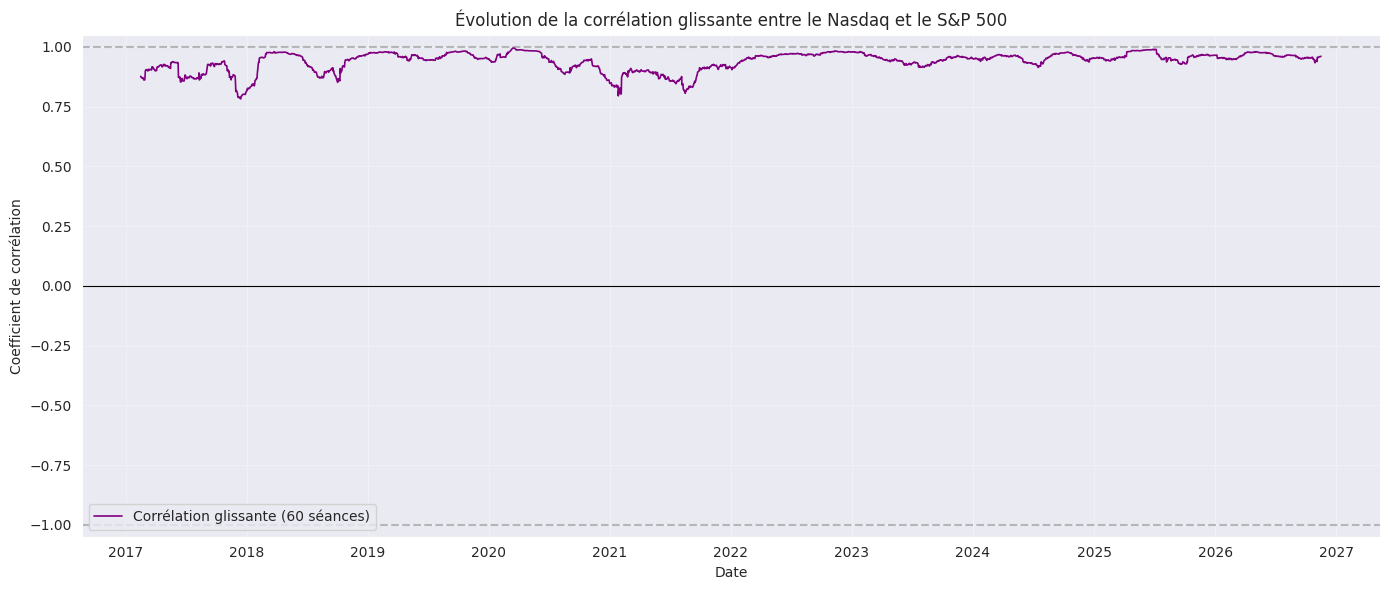

In [24]:
plt.figure(figsize=(14, 6))

plt.plot(
    donnees_ml.index,
    donnees_ml["corr_60"],
    color="purple",
    linewidth=1.2,
    label="Corrélation glissante (60 séances)"
)

plt.axhline(0, color="black", linewidth=0.8)
plt.axhline(1, color="gray", linestyle="--", alpha=0.5)
plt.axhline(-1, color="gray", linestyle="--", alpha=0.5)

plt.title("Évolution de la corrélation glissante entre le Nasdaq et le S&P 500")
plt.xlabel("Date")
plt.ylabel("Coefficient de corrélation")
plt.ylim(-1.05, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interprétation de la corrélation glissante

Le graphique montre que la corrélation glissante entre le Nasdaq et le S&P 500 reste fortement positive sur l'ensemble de la période étudiée. Le coefficient se situe généralement entre 0,80 et 1,00.

Des diminutions ponctuelles sont toutefois observées, notamment autour de 2018, 2020 et 2021, ce qui traduit des variations dans l'intensité de la relation entre les deux indices.

Depuis 2022, la corrélation semble relativement stable, avec un coefficient généralement proche de 0,95.

Ces observations montrent que les deux indices présentent une forte dépendance linéaire, mais que l'intensité de cette relation évolue dans le temps.

# Construire la variable cible : horizon de 20 séances

In [25]:
# Corrélation observée 20 séances plus tard
donnees_ml["corr_future_20"] = donnees_ml["corr_60"].shift(-20)

# Construction de la variable cible
donnees_ml["target"] = (
    donnees_ml["corr_future_20"] > donnees_ml["corr_60"]
).astype(int)

# Suppression des observations incomplètes
donnees_ml = donnees_ml.dropna()

# Vérification
print(donnees_ml.head())
print("\nDimensions :", donnees_ml.shape)
print("\nRépartition des classes :")
print(donnees_ml["target"].value_counts())

              Nasdaq     SP500   corr_60  corr_future_20  target
Date                                                            
2017-02-15  0.637608  0.499231  0.876320        0.905163       1
2017-02-16 -0.078015 -0.086412  0.875627        0.905072       1
2017-02-17  0.407233  0.167856  0.870469        0.903061       1
2017-02-21  0.468780  0.604807  0.869562        0.915948       1
2017-02-22 -0.090698 -0.108220  0.870932        0.915719       1

Dimensions : (2432, 5)

Répartition des classes :
target
1    1237
0    1195
Name: count, dtype: int64


# Vérification méthodologique

In [26]:
# Vérification des dernières observations
print(donnees_ml.tail(25)[
    ["corr_60", "corr_future_20", "target"]
])

print("\nValeurs manquantes :")
print(donnees_ml.isnull().sum())

print("\nRépartition des classes en pourcentage :")
print(
    donnees_ml["target"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

             corr_60  corr_future_20  target
Date                                        
2026-09-15  0.951065        0.953400       1
2026-09-16  0.949990        0.954508       1
2026-09-17  0.948341        0.954104       1
2026-09-18  0.948485        0.952799       1
2026-09-21  0.952861        0.955052       1
2026-09-22  0.951476        0.953796       1
2026-09-23  0.950667        0.956290       1
2026-09-24  0.950134        0.955486       1
2026-09-25  0.950229        0.948208       0
2026-09-28  0.954737        0.947625       0
2026-09-29  0.953834        0.944010       0
2026-09-30  0.952255        0.936582       0
2026-10-01  0.954486        0.932971       0
2026-10-02  0.954295        0.942270       0
2026-10-05  0.955739        0.942016       0
2026-10-06  0.954094        0.942379       0
2026-10-07  0.954672        0.937906       0
2026-10-08  0.952971        0.956082       1
2026-10-09  0.955627        0.953817       0
2026-10-12  0.953048        0.956613       1
2026-10-13

# Sélectionner les variables explicatives

In [27]:
# Sélection des variables explicatives
X = donnees_ml[["Nasdaq", "SP500", "corr_60"]]

# Sélection de la variable cible
y = donnees_ml["target"]

# Vérification
print("Dimensions des variables explicatives :", X.shape)
print("Dimensions de la variable cible :", y.shape)

print("\nAperçu des variables explicatives :")
print(X.head())

print("\nAperçu de la variable cible :")
print(y.head())

Dimensions des variables explicatives : (2432, 3)
Dimensions de la variable cible : (2432,)

Aperçu des variables explicatives :
              Nasdaq     SP500   corr_60
Date                                    
2017-02-15  0.637608  0.499231  0.876320
2017-02-16 -0.078015 -0.086412  0.875627
2017-02-17  0.407233  0.167856  0.870469
2017-02-21  0.468780  0.604807  0.869562
2017-02-22 -0.090698 -0.108220  0.870932

Aperçu de la variable cible :
Date
2017-02-15    1
2017-02-16    1
2017-02-17    1
2017-02-21    1
2017-02-22    1
Name: target, dtype: int64


# Séparation chronologique des données

In [28]:
# Détermination des indices de séparation
n = len(X)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

# Séparation chronologique
X_train = X.iloc[:train_end]
y_train = y.iloc[:train_end]

X_val = X.iloc[train_end:val_end]
y_val = y.iloc[train_end:val_end]

X_test = X.iloc[val_end:]
y_test = y.iloc[val_end:]

# Vérification des dimensions
print("Ensemble d'entraînement :", X_train.shape, y_train.shape)
print("Ensemble de validation :", X_val.shape, y_val.shape)
print("Ensemble de test :", X_test.shape, y_test.shape)

# Vérification des périodes
print("\nPériode d'entraînement :", X_train.index.min(), "à", X_train.index.max())
print("Période de validation :", X_val.index.min(), "à", X_val.index.max())
print("Période de test :", X_test.index.min(), "à", X_test.index.max())

Ensemble d'entraînement : (1702, 3) (1702,)
Ensemble de validation : (365, 3) (365,)
Ensemble de test : (365, 3) (365,)

Période d'entraînement : 2017-02-15 00:00:00 à 2023-11-17 00:00:00
Période de validation : 2023-11-20 00:00:00 à 2025-05-06 00:00:00
Période de test : 2025-05-07 00:00:00 à 2026-10-19 00:00:00


In [29]:
# Séparation chronologique avec purge de 20 séances
n = len(X)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

horizon = 20

# Entraînement : retrait des 20 dernières observations
X_train = X.iloc[:train_end - horizon]
y_train = y.iloc[:train_end - horizon]

# Validation : retrait des 20 dernières observations
X_val = X.iloc[train_end:val_end - horizon]
y_val = y.iloc[train_end:val_end - horizon]

# Test : conservation de la dernière période
X_test = X.iloc[val_end:]
y_test = y.iloc[val_end:]

# Vérification
print("Entraînement :", X_train.shape, y_train.shape)
print("Validation :", X_val.shape, y_val.shape)
print("Test :", X_test.shape, y_test.shape)

print("\nPériodes :")
print("Entraînement :", X_train.index.min(), "à", X_train.index.max())
print("Validation :", X_val.index.min(), "à", X_val.index.max())
print("Test :", X_test.index.min(), "à", X_test.index.max())

Entraînement : (1682, 3) (1682,)
Validation : (345, 3) (345,)
Test : (365, 3) (365,)

Périodes :
Entraînement : 2017-02-15 00:00:00 à 2023-10-20 00:00:00
Validation : 2023-11-20 00:00:00 à 2025-04-07 00:00:00
Test : 2025-05-07 00:00:00 à 2026-10-19 00:00:00


# Préparqtion de  la régression logistique

In [30]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Création du pipeline
modele = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(max_iter=1000, random_state=42))
])

print("Pipeline créé avec succès.")
print(modele)

Pipeline créé avec succès.
Pipeline(steps=[('scaler', StandardScaler()),
                ('logistic',
                 LogisticRegression(max_iter=1000, random_state=42))])


# Entraînement du modèle

In [31]:
# Entraînement du modèle
modele.fit(X_train, y_train)

print("Modèle entraîné avec succès !")

# Affichage des paramètres appris
print("\nCoefficients du modèle :")
print(modele.named_steps["logistic"].coef_)

print("\nConstante (intercept) :")
print(modele.named_steps["logistic"].intercept_)

Modèle entraîné avec succès !

Coefficients du modèle :
[[-0.15393051  0.02410384 -0.42177068]]

Constante (intercept) :
[0.07905335]


In [32]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Prédictions sur l'ensemble de validation
y_val_pred = modele.predict(X_val)

# Calcul des métriques
print("Accuracy :", round(accuracy_score(y_val, y_val_pred), 4))
print("Precision :", round(precision_score(y_val, y_val_pred), 4))
print("Recall :", round(recall_score(y_val, y_val_pred), 4))
print("F1-score :", round(f1_score(y_val, y_val_pred), 4))

# Matrice de confusion
print("\nMatrice de confusion :")
print(confusion_matrix(y_val, y_val_pred))

# Rapport de classification
print("\nRapport de classification :")
print(classification_report(y_val, y_val_pred))

Accuracy : 0.5652
Precision : 0.7246
Recall : 0.2762
F1-score : 0.4

Matrice de confusion :
[[145  19]
 [131  50]]

Rapport de classification :
              precision    recall  f1-score   support

           0       0.53      0.88      0.66       164
           1       0.72      0.28      0.40       181

    accuracy                           0.57       345
   macro avg       0.62      0.58      0.53       345
weighted avg       0.63      0.57      0.52       345



In [33]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

# Création de la baseline
baseline = DummyClassifier(strategy="most_frequent")

# Entraînement sur les données d'entraînement
baseline.fit(X_train, y_train)

# Prédictions sur la validation
y_val_baseline = baseline.predict(X_val)

# Évaluation
print("Résultats de la baseline :")
print("Accuracy :", round(accuracy_score(y_val, y_val_baseline), 4))
print("F1-score :", round(f1_score(y_val, y_val_baseline, zero_division=0), 4))

print("\nClasse prédite systématiquement :")
print(baseline.classes_[baseline.class_prior_.argmax()])

Résultats de la baseline :
Accuracy : 0.5246
F1-score : 0.6882

Classe prédite systématiquement :
1


In [34]:
from sklearn.metrics import (
    f1_score,
    balanced_accuracy_score,
    classification_report
)

# Métriques de la régression logistique
print("RÉGRESSION LOGISTIQUE")
print("Macro-F1 :", round(
    f1_score(y_val, y_val_pred, average="macro"), 4
))
print("Balanced Accuracy :", round(
    balanced_accuracy_score(y_val, y_val_pred), 4
))

# Métriques de la baseline
print("\nBASELINE")
print("Macro-F1 :", round(
    f1_score(y_val, y_val_baseline, average="macro"), 4
))
print("Balanced Accuracy :", round(
    balanced_accuracy_score(y_val, y_val_baseline), 4
))

RÉGRESSION LOGISTIQUE
Macro-F1 : 0.5295
Balanced Accuracy : 0.5802

BASELINE
Macro-F1 : 0.3441
Balanced Accuracy : 0.5


In [35]:
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import f1_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Hyperparamètres à tester
parametres = {
    "logistic__C": [0.1, 1, 10],
    "logistic__class_weight": [None, "balanced"]
}

resultats = []

# Tester les différentes combinaisons
for params in ParameterGrid(parametres):

    modele_test = Pipeline([
        ("scaler", StandardScaler()),
        ("logistic", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ])

    modele_test.set_params(**params)

    modele_test.fit(X_train, y_train)

    predictions = modele_test.predict(X_val)

    macro_f1 = f1_score(
        y_val,
        predictions,
        average="macro"
    )

    resultats.append({
        "C": params["logistic__C"],
        "class_weight": params["logistic__class_weight"],
        "Macro-F1": macro_f1
    })

# Affichage des résultats
tableau_resultats = pd.DataFrame(resultats)

print(tableau_resultats.sort_values(
    by="Macro-F1",
    ascending=False
).to_string(index=False))

   C class_weight  Macro-F1
 0.1         None  0.529545
 1.0         None  0.529545
10.0         None  0.529545
 1.0     balanced  0.464875
10.0     balanced  0.464875
 0.1     balanced  0.460094


In [36]:
# Configuration retenue
modele_final = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        C=1.0,
        class_weight=None,
        max_iter=1000,
        random_state=42
    ))
])

# Entraînement sur l'ensemble d'entraînement
modele_final.fit(X_train, y_train)

print("Configuration finale retenue :")
print(modele_final)

Configuration finale retenue :
Pipeline(steps=[('scaler', StandardScaler()),
                ('logistic',
                 LogisticRegression(max_iter=1000, random_state=42))])


In [37]:
# Réunir les données d'entraînement et de validation
X_train_val = pd.concat([X_train, X_val])
y_train_val = pd.concat([y_train, y_val])

# Réentraîner le modèle sur les données réunies
modele_final.fit(X_train_val, y_train_val)

# Prédictions sur l'ensemble de test
y_test_pred = modele_final.predict(X_test)

print("Modèle réentraîné sur train + validation.")
print("Prédictions sur le test :", len(y_test_pred))

Modèle réentraîné sur train + validation.
Prédictions sur le test : 365


# Évaluer les performances finales

In [38]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)

# Calcul des métriques sur le test
print("ÉVALUATION FINALE — ENSEMBLE DE TEST\n")

print("Accuracy :", round(accuracy_score(y_test, y_test_pred), 4))
print("Precision :", round(precision_score(y_test, y_test_pred, zero_division=0), 4))
print("Recall :", round(recall_score(y_test, y_test_pred, zero_division=0), 4))
print("F1-score :", round(f1_score(y_test, y_test_pred, zero_division=0), 4))
print("Macro-F1 :", round(f1_score(y_test, y_test_pred, average="macro"), 4))
print("Balanced Accuracy :", round(balanced_accuracy_score(y_test, y_test_pred), 4))

print("\nMatrice de confusion :")
print(confusion_matrix(y_test, y_test_pred))

print("\nRapport de classification :")
print(classification_report(y_test, y_test_pred, zero_division=0))

ÉVALUATION FINALE — ENSEMBLE DE TEST

Accuracy : 0.6548
Precision : 0.7636
Recall : 0.271
F1-score : 0.4
Macro-F1 : 0.5788
Balanced Accuracy : 0.6045

Matrice de confusion :
[[197  13]
 [113  42]]

Rapport de classification :
              precision    recall  f1-score   support

           0       0.64      0.94      0.76       210
           1       0.76      0.27      0.40       155

    accuracy                           0.65       365
   macro avg       0.70      0.60      0.58       365
weighted avg       0.69      0.65      0.61       365



In [39]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score
)

# Baseline entraînée sur train + validation
baseline_finale = DummyClassifier(strategy="most_frequent")
baseline_finale.fit(X_train_val, y_train_val)

# Prédictions sur le test
y_test_baseline = baseline_finale.predict(X_test)

# Tableau comparatif
comparaison_test = pd.DataFrame({
    "Métrique": ["Accuracy", "Macro-F1", "Balanced Accuracy"],
    "Régression logistique": [
        accuracy_score(y_test, y_test_pred),
        f1_score(y_test, y_test_pred, average="macro"),
        balanced_accuracy_score(y_test, y_test_pred)
    ],
    "Baseline": [
        accuracy_score(y_test, y_test_baseline),
        f1_score(y_test, y_test_baseline, average="macro"),
        balanced_accuracy_score(y_test, y_test_baseline)
    ]
})

print(comparaison_test.round(4))

            Métrique  Régression logistique  Baseline
0           Accuracy                 0.6548    0.4247
1           Macro-F1                 0.5788    0.2981
2  Balanced Accuracy                 0.6045    0.5000


### Bilan de l'évaluation du modèle

L'évaluation finale de la régression logistique sur l'ensemble de test donne une accuracy de 65,48 %, un Macro-F1 de 0,5788 et une Balanced Accuracy de 60,45 %.

La comparaison avec le modèle de référence (baseline) montre une amélioration sur les trois indicateurs. En particulier, le Macro-F1 passe de 0,2981 pour la baseline à 0,5788 pour la régression logistique.

Ces résultats indiquent que le modèle possède une capacité de classification supérieure à une stratégie naïve. Toutefois, son rappel pour la classe 1 reste limité à 27,10 %. Il détecte donc seulement une partie des augmentations réelles de la corrélation.

En conclusion, la régression logistique apporte une valeur prédictive intéressante, mais ses performances restent modérées et doivent être interprétées avec prudence.

# Visualisqtion des erreurs du modèle

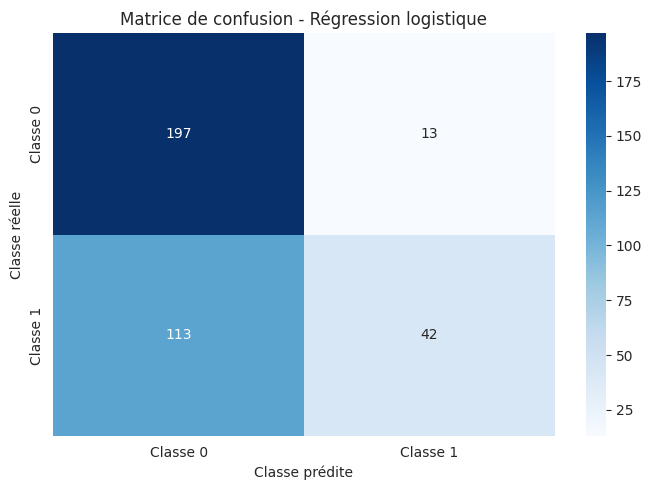

In [40]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Matrice de confusion
cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Classe 0", "Classe 1"],
    yticklabels=["Classe 0", "Classe 1"]
)

plt.title("Matrice de confusion - Régression logistique")
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.tight_layout()
plt.show()

In [41]:
# Création d'un tableau regroupant les résultats
analyse_erreurs = pd.DataFrame({
    "Classe_reelle": y_test,
    "Classe_predite": y_test_pred
})

# Identification des erreurs
erreurs = analyse_erreurs[
    analyse_erreurs["Classe_reelle"] != analyse_erreurs["Classe_predite"]
].copy()

# Catégorisation des erreurs
erreurs["Type_erreur"] = erreurs.apply(
    lambda ligne: (
        "Hausse non détectée"
        if ligne["Classe_reelle"] == 1
        else "Fausse alerte de hausse"
    ),
    axis=1
)

print("Nombre total d'erreurs :", len(erreurs))

print("\nRépartition des erreurs :")
print(erreurs["Type_erreur"].value_counts())

print("\nQuelques observations mal classées :")
print(erreurs.head(10))

Nombre total d'erreurs : 126

Répartition des erreurs :
Type_erreur
Hausse non détectée        113
Fausse alerte de hausse     13
Name: count, dtype: int64

Quelques observations mal classées :
            Classe_reelle  Classe_predite          Type_erreur
Date                                                          
2025-05-07              1               0  Hausse non détectée
2025-05-08              1               0  Hausse non détectée
2025-05-09              1               0  Hausse non détectée
2025-05-12              1               0  Hausse non détectée
2025-05-13              1               0  Hausse non détectée
2025-05-14              1               0  Hausse non détectée
2025-05-15              1               0  Hausse non détectée
2025-05-16              1               0  Hausse non détectée
2025-05-19              1               0  Hausse non détectée
2025-05-20              1               0  Hausse non détectée


In [42]:
# Probabilités prédites sur l'ensemble de test
probabilites = modele_final.predict_proba(X_test)

# Création d'un tableau d'analyse
analyse_probabilites = pd.DataFrame({
    "Classe_reelle": y_test,
    "Classe_predite": y_test_pred,
    "Probabilite_classe_0": probabilites[:, 0],
    "Probabilite_classe_1": probabilites[:, 1]
}, index=y_test.index)

# Analyse des probabilités selon la classe réelle
print("Probabilités moyennes selon la classe réelle :")

print(
    analyse_probabilites.groupby("Classe_reelle")[
        ["Probabilite_classe_0", "Probabilite_classe_1"]
    ].mean().round(4)
)

print("\nProbabilités moyennes des erreurs :")

print(
    analyse_probabilites.loc[erreurs.index][
        ["Probabilite_classe_0", "Probabilite_classe_1"]
    ].mean().round(4)
)

Probabilités moyennes selon la classe réelle :
               Probabilite_classe_0  Probabilite_classe_1
Classe_reelle                                            
0                            0.5557                0.4443
1                            0.5355                0.4645

Probabilités moyennes des erreurs :
Probabilite_classe_0    0.5492
Probabilite_classe_1    0.4508
dtype: float64


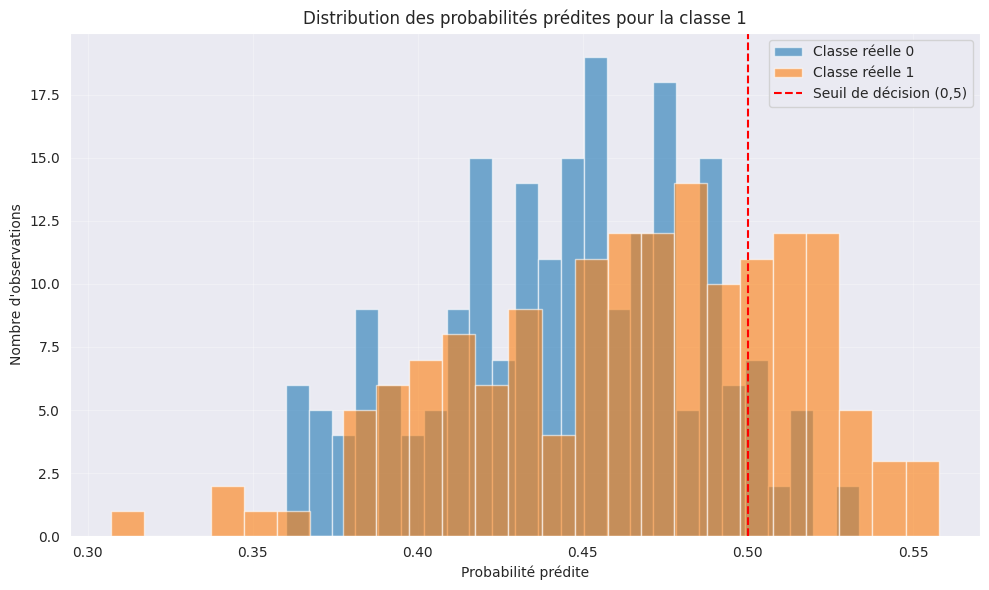

In [43]:
plt.figure(figsize=(10, 6))

plt.hist(
    analyse_probabilites.loc[
        analyse_probabilites["Classe_reelle"] == 0,
        "Probabilite_classe_1"
    ],
    bins=25,
    alpha=0.6,
    label="Classe réelle 0"
)

plt.hist(
    analyse_probabilites.loc[
        analyse_probabilites["Classe_reelle"] == 1,
        "Probabilite_classe_1"
    ],
    bins=25,
    alpha=0.6,
    label="Classe réelle 1"
)

plt.axvline(
    0.5,
    color="red",
    linestyle="--",
    label="Seuil de décision (0,5)"
)

plt.title("Distribution des probabilités prédites pour la classe 1")
plt.xlabel("Probabilité prédite")
plt.ylabel("Nombre d'observations")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Analyse de la distribution des probabilités prédites

La distribution des probabilités attribuées à la classe 1 montre un chevauchement important entre les observations appartenant réellement aux classes 0 et 1.

La majorité des probabilités se situe dans une zone relativement proche du seuil de décision de 0,5. Cette proximité traduit une difficulté du modèle à distinguer clairement les deux catégories.

On observe également que plusieurs observations appartenant réellement à la classe 1 reçoivent une probabilité inférieure à 0,5. Elles sont donc classées à tort dans la classe 0.

Cette analyse permet de mieux comprendre le faible rappel obtenu pour la classe 1 et souligne les limites de la régression logistique dans la prédiction des variations futures de la corrélation.